# Fibre modes: slab, step and graded index, and the single-mode condition

Notebook 115 (light in a fibre) followed rays. Rays are fine as long as the core is many
wavelengths wide, but they miss two things: light in a waveguide only
propagates in a discrete set of field patterns, the **modes**, and a core
thin enough supports only one of them. This notebook builds the mode
picture and connects it to the rays:

1. the slab waveguide, where each mode is a ray direction that interferes
   constructively with itself (the transverse resonance condition),
2. the step-index fibre: the b–V diagram, cutoffs, the number of modes and
   the single-mode condition,
3. the exact vector modes (HE, EH, TE, TM) and why the scalar LP modes are
   good enough for weakly guiding fibres,
4. the mode field diameter of a single-mode fibre and the loss of a splice,
5. modes of graded-index fibres from a radial mode solver: mode groups and
   their ray families,
6. the bend loss of the single-mode fibre.

The step-index LP modes and the coupling helpers are in `pyoptics.modes`
(notebook 09, mode analysis). `pyoptics.fibres` adds the radial finite-volume solver
`scalar_modes()` for any index profile, the exact `vector_modes()`, the
Petermann mode field diameter and Marcuse's bend loss. Lengths in µm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fibres, modes, interfaces, sketch
from pyoptics.fdtd import modes as fdtd_modes
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. From rays to modes in a slab

A plane wave in a slab of thickness $d$ zigzags at the angle $\theta$ to the
axis. Its wave vector has the component $\beta = kn_1\cos\theta$ along the
slab and $k_x = kn_1\sin\theta$ across. Going up and down once, the wave
gains the phase $2k_xd$ and the two phases of total internal reflection,
$\arg r$ at each interface (from `interfaces.r_s()` for TE, `r_p()` for TM,
beyond the critical angle $|r| = 1$). The wave is a mode only if it
matches itself after the round trip:

$$
2kn_1d\sin\theta + 2\arg r(90° - \theta) = 2\pi m, \qquad m = 0, 1, 2, \dots
$$

Only a discrete set of angles, and of propagation constants
$\beta = kn_1\cos\theta$, survives. Below, the condition is solved for a
slab of $n_1 = 1.50$ in $n_2 = 1.45$ and compared with the finite-difference
mode solver of the FDTD (notebook 60, FDTD photonic circuits) for the continuous problem.

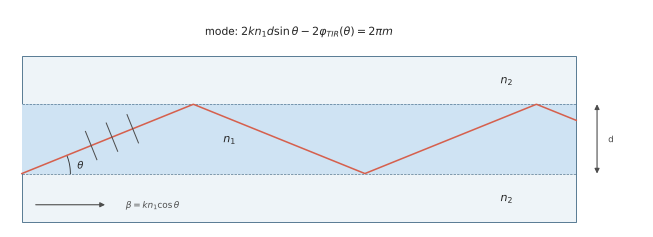

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sketch.slab_transverse_resonance(ax)
plt.show()

TE: n_eff from the ray condition [1.496437 1.485904 1.469131 1.450438]
TE: n_eff from the mode solver    [1.49643  1.485876 1.469073 1.450286]
TM: n_eff from the ray condition [1.496359 1.485635 1.468725 1.450399]
TM: n_eff from the mode solver    [1.496351 1.485606 1.468667 1.450238]


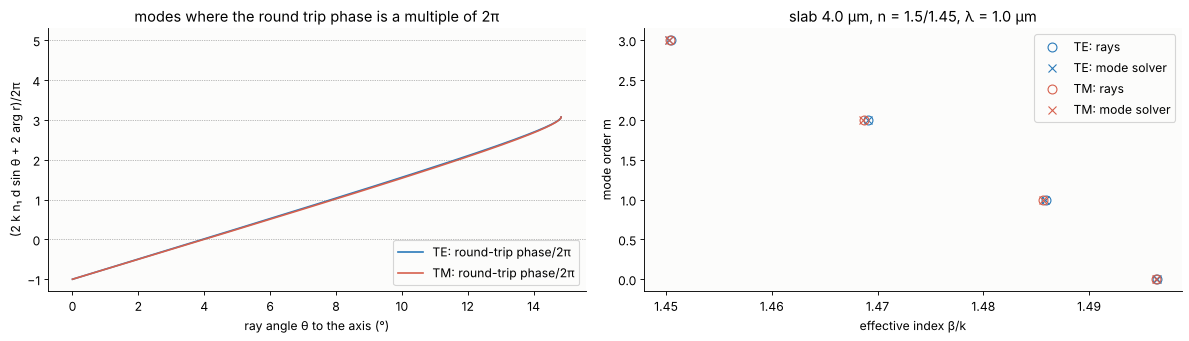

In [3]:
n1s, n2s, d, wl = 1.50, 1.45, 4.0, 1.0
k = 2*np.pi/wl
theta = np.linspace(1E-6, np.arccos(n2s/n1s) - 1E-9, 20001)


def phase_mismatch(theta, pol):
    r = (interfaces.r_s if pol == "TE" else interfaces.r_p)(np.pi/2 - theta, n1s, n2s)
    return 2*k*n1s*d*np.sin(theta) + 2*np.angle(r)


x = np.linspace(-8, 8, 3201)
h = x[1] - x[0]
eps = np.where(np.abs(x) < d/2, n1s**2, n2s**2)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for pol, solver_mode, c in (("TE", "Ez", BLUE), ("TM", "Hz", RED)):
    ph = phase_mismatch(theta, pol)/(2*np.pi)
    axes[0].plot(np.degrees(theta), ph, color=c, label=pol + ": round-trip phase/2π")
    roots = []
    for m in range(0, int(ph.max()) + 1):
        i = np.nonzero((ph[:-1] < m) & (ph[1:] >= m))[0]
        if len(i):
            j = i[0]
            t = theta[j] + (m - ph[j])/(ph[j + 1] - ph[j])*(theta[j + 1] - theta[j])
            roots.append(n1s*np.cos(t))
    fd = [mo.n_eff for mo in fdtd_modes.waveguide_modes(eps, h, wl, mode=solver_mode, num_modes=10,
                                                        coords=x)]
    print(f"{pol}: n_eff from the ray condition", np.round(roots, 6))
    print(f"{pol}: n_eff from the mode solver   ", np.round(fd, 6))
    axes[1].plot(roots, np.arange(len(roots)), "o", color=c, ms=8, mfc="none", label=pol + ": rays")
    axes[1].plot(fd, np.arange(len(fd)), "x", color=c, ms=7, label=pol + ": mode solver")
for m in range(0, 6):
    axes[0].axhline(m, color=GREY, lw=0.6, ls=":")
axes[0].set_xlabel("ray angle θ to the axis (°)"); axes[0].set_ylabel("(2 k n₁ d sin θ + 2 arg r)/2π")
axes[0].set_title("modes where the round trip phase is a multiple of 2π"); axes[0].legend()
axes[1].set_xlabel("effective index β/k"); axes[1].set_ylabel("mode order m")
axes[1].set_title(f"slab {d} µm, n = {n1s}/{n2s}, λ = {wl} µm"); axes[1].legend()
plt.tight_layout()
plt.show()

The ray condition and the solver agree to $10^{-5}$ for the well guided
modes and to $2\cdot 10^{-4}$ for the last one, whose tails reach the walls
of the 16 µm solver window. Each mode is a pair of plane waves at a definite
angle; the mode field across the slab is their interference pattern
(a cosine or sine with $m$ zeros), with evanescent tails outside whose decay
length grows as the mode approaches cutoff ($\theta \to \theta_c$). TM modes
have slightly lower effective indices: their reflection phase is larger.
The number of modes grows with $d$; the lowest mode of a symmetric slab
never cuts off.

## 2. The step-index fibre: b–V diagram and the single-mode condition

In a round core the same idea leads to Bessel functions $J_l$ in the core
and $K_l$ in the cladding (notebook 09, mode analysis, section 4). For a weakly guiding
fibre ($\Delta \ll 1$) the modes are the linearly polarized LP$_{lm}$ modes,
and everything depends on one number, the **V number**

$$
V = \frac{2\pi a}{\lambda}\,\mathrm{NA},
$$

through the normalized propagation constant
$b = (n_{eff}^2 - n_2^2)/(n_1^2 - n_2^2) \in (0, 1)$. LP$_{lm}$ is cut off
where $b \to 0$, at the zeros of $J_{l-1}$. LP$_{01}$ has no cutoff; the
next mode, LP$_{11}$, appears at $V = 2.405$. Below that value the fibre is
**single mode**. For large $V$ the number of modes (counting the two
polarizations and the two orientations $\cos l\varphi$, $\sin l\varphi$)
approaches $V^2/2$.

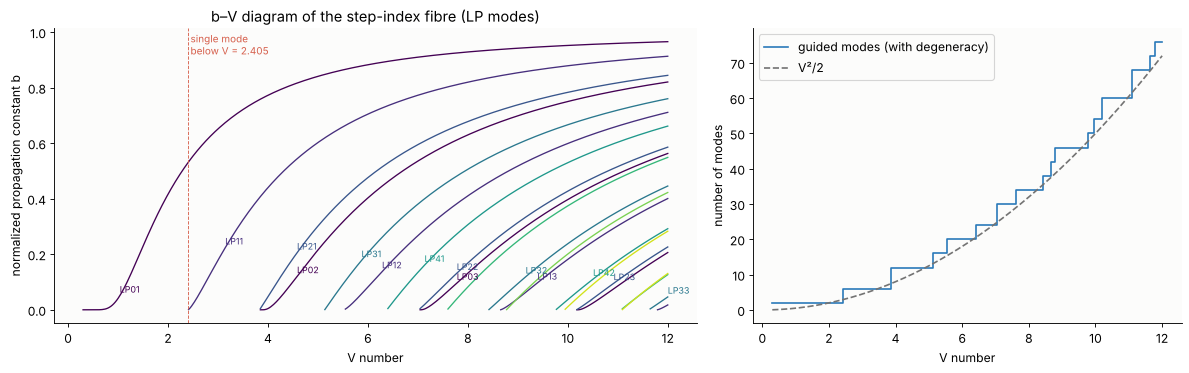

In [4]:
Vs = np.linspace(0.3, 12, 400)
curves = {}
for V in Vs:
    for mo in modes.lp_modes(V):
        curves.setdefault((mo.l, mo.m), []).append((V, mo.b))
counts = [sum(mo.degeneracy for mo in modes.lp_modes(V)) for V in Vs]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
cmap = plt.cm.viridis
for (l, m), pts in sorted(curves.items()):
    pts = np.array(pts)
    axes[0].plot(pts[:, 0], pts[:, 1], color=cmap(min(l, 7)/7.5), lw=1.2)
    if l <= 4 and m <= 3:
        i = min(len(pts) - 1, 25)
        axes[0].text(pts[i, 0], pts[i, 1] + 0.012, f"LP{l}{m}", fontsize=8, color=cmap(min(l, 7)/7.5))
axes[0].axvline(2.405, color=RED, ls="--", lw=0.8)
axes[0].text(2.45, 0.92, "single mode\nbelow V = 2.405", color=RED, fontsize=9)
axes[0].set_xlabel("V number"); axes[0].set_ylabel("normalized propagation constant b")
axes[0].set_title("b–V diagram of the step-index fibre (LP modes)")
axes[1].step(Vs, counts, where="post", color=BLUE, label="guided modes (with degeneracy)")
axes[1].plot(Vs, Vs**2/2, color=GREY, ls="--", label="V²/2")
axes[1].set_xlabel("V number"); axes[1].set_ylabel("number of modes"); axes[1].legend()
plt.tight_layout()
plt.show()

For the standard single-mode fibre (the step-index model `fibres.smf28()`:
a 4.4 µm core radius, 3.2 mol-% GeO₂ in the core, a pure silica cladding,
indices from Fleming's Sellmeier data in `materials.germania_silica_index()`)
the cutoff wavelength $\lambda_c = 2\pi a\,\mathrm{NA}/2.405$ lies at
1.35 µm: below it LP$_{11}$ is guided too. In practice LP$_{11}$ near its
cutoff is so weakly guided that a few bends in a cable strip it; the
specified "cable cutoff" of a G.652 fibre is 1.26 µm, which is why the
O band starts there. A 50 µm step-index core at 850 nm carries some 700
modes, the graded-index fibre half as many. Below, the mode fields of a few-mode fibre (V = 6).

SMF model: NA = 0.118, Delta = 0.329%, cutoff wavelength 1.353 µm
  λ = 0.85 µm: V = 3.841, guided LP modes: LP01, LP11, LP21, LP02
  λ = 1.31 µm: V = 2.484, guided LP modes: LP01, LP11
  λ = 1.55 µm: V = 2.103, guided LP modes: LP01


50 µm step-index core at 850 nm: V = 37.3, 704 modes (V²/2 = 697)


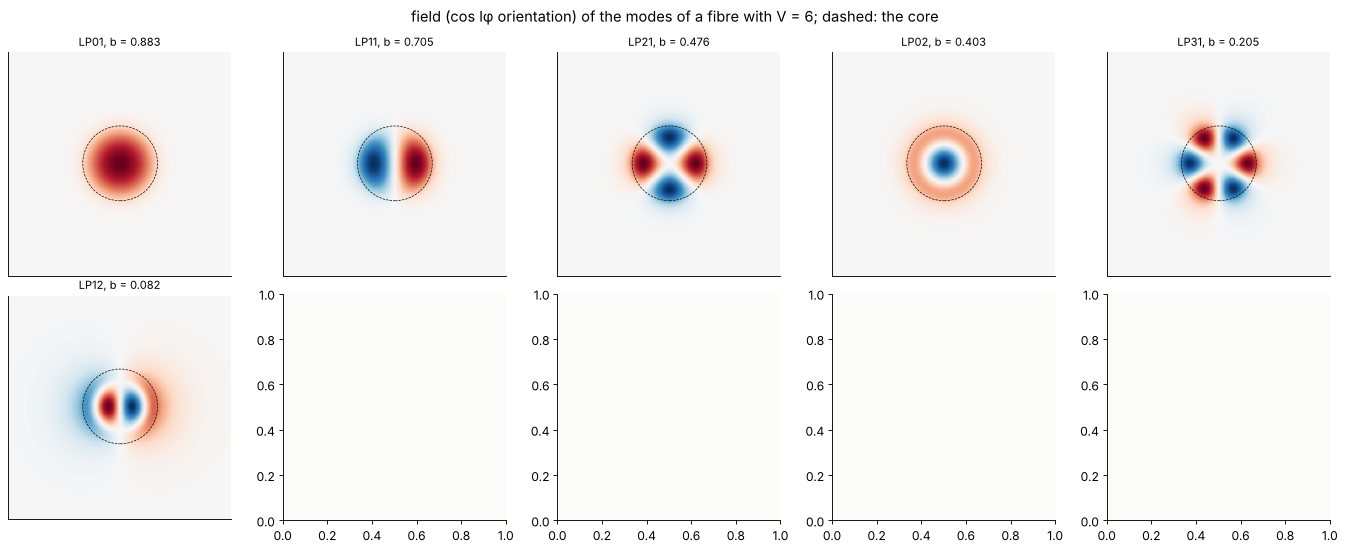

In [5]:
smf = fibres.smf28()
wls = np.array([0.85, 1.31, 1.55])
lam_c = 2*np.pi*smf.a*smf.NA(1.31)/2.405
print("SMF model: NA = {:.3f}, Delta = {:.3%}, cutoff wavelength {:.3f} µm".format(
      smf.NA(1.31), smf.delta(1.31), lam_c))
for w in wls:
    ms = modes.lp_modes(smf.V(w))
    print("  λ = {:.2f} µm: V = {:.3f}, guided LP modes: {}".format(
          w, smf.V(w), ", ".join(f"LP{m.l}{m.m}" for m in ms)))
mm = fibres.step_index(25.0, 1.464, 1.450)
print("50 µm step-index core at 850 nm: V = {:.1f}, {} modes (V²/2 = {:.0f})".format(
      mm.V(0.85), sum(m.degeneracy for m in modes.lp_modes(mm.V(0.85))), mm.V(0.85)**2/2))

x, y, X, Y = grid2d(-12, 12, -12, 12, 181)
few = modes.lp_modes(6.0)
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, mo in zip(axes.flat, few[:10]):
    f = modes.lp_mode_field(mo, x, y, 4.0)
    ax.imshow(np.real(f), extent=[x[0], x[-1], y[0], y[-1]], cmap="RdBu_r", origin="lower",
              vmin=-np.abs(f).max(), vmax=np.abs(f).max())
    ax.add_patch(plt.Circle((0, 0), 4.0, fill=False, color="k", lw=0.6, ls="--"))
    ax.set_title(f"LP{mo.l}{mo.m}, b = {mo.b:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("field (cos lφ orientation) of the modes of a fibre with V = 6; dashed: the core", y=0.98)
plt.tight_layout()
plt.show()

## 3. Exact vector modes against LP modes

The LP modes come from the scalar wave equation, which neglects that the
field direction must change at the core boundary. The exact modes of the
step-index fibre are the hybrid HE$_{\nu m}$ and EH$_{\nu m}$ modes and the
TE$_{0m}$ and TM$_{0m}$ modes, from the eigenvalue equations in
`fibres.vector_modes()` (Snyder and Love, chapter 12). Each LP mode is a
group of nearly degenerate exact modes: LP$_{01}$ is HE$_{11}$ (two
polarizations), LP$_{11}$ is TE$_{01}$, TM$_{01}$ and HE$_{21}$, and in
general LP$_{lm}$ = HE$_{l+1,m}$ + EH$_{l-1,m}$ (TE/TM for $l = 1$). Their
effective indices differ by a small amount that vanishes as $\Delta \to 0$.
The splitting matters in practice: it makes a "linearly polarized" LP$_{11}$
pattern rotate along the fibre, and it is the beat length of polarization
effects in few-mode fibres.

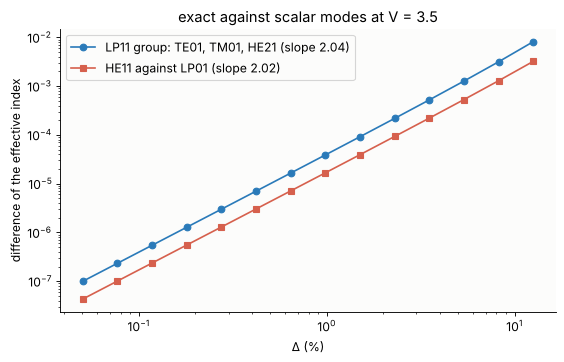

SMF at 1550 nm: HE11 n_eff = 1.44617754, LP01 n_eff = 1.44618181


In [6]:
n1v, V0, wlv = 1.46, 3.5, 1.0
Deltas = np.logspace(-3.3, -0.9, 14)
split11, split01 = [], []
for D in Deltas:
    n2v = n1v*np.sqrt(1 - 2*D)
    a_v = V0*wlv/(2*np.pi*np.sqrt(n1v**2 - n2v**2))
    vm = fibres.vector_modes(a_v, n1v, n2v, wlv, nu_max=3)
    lp = modes.lp_modes(core_radius=a_v, n_core=n1v, n_clad=n2v, wavelength=wlv)
    group = [m.n_eff for m in vm if m.m == 1 and (m.kind, m.nu) in (("TE", 0), ("TM", 0), ("HE", 2))]
    split11.append(np.ptp(group))
    he11 = [m.n_eff for m in vm if (m.kind, m.nu, m.m) == ("HE", 1, 1)][0]
    split01.append(abs(he11 - lp[0].n_eff))
p11 = np.polyfit(np.log(Deltas), np.log(split11), 1)[0]
p01 = np.polyfit(np.log(Deltas), np.log(split01), 1)[0]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.loglog(Deltas*100, split11, "o-", color=BLUE, label=f"LP11 group: TE01, TM01, HE21 (slope {p11:.2f})")
ax.loglog(Deltas*100, split01, "s-", color=RED, label=f"HE11 against LP01 (slope {p01:.2f})")
ax.set_xlabel("Δ (%)"); ax.set_ylabel("difference of the effective index")
ax.set_title(f"exact against scalar modes at V = {V0}"); ax.legend()
plt.show()
vm = fibres.vector_modes(smf.a, float(smf.n_core(1.55)), float(smf.n_clad(1.55)), 1.55)
lp = modes.lp_modes(core_radius=smf.a, n_core=float(smf.n_core(1.55)), n_clad=float(smf.n_clad(1.55)),
                    wavelength=1.55)
print("SMF at 1550 nm: HE11 n_eff = {:.8f}, LP01 n_eff = {:.8f}".format(vm[0].n_eff, lp[0].n_eff))

At a fixed V the splitting grows as $\Delta^2$ (Snyder and Love's
polarization correction is $\propto\Delta^{3/2}/a$, and $a \propto
\Delta^{-1/2}$ at fixed V). At the 0.3 % of a single-mode fibre it is a few
parts in $10^6$ of the index, far below everything else that
matters (the difference between HE$_{11}$ and LP$_{01}$ hardly changes the
dispersion of notebook 117, dispersion in fibres). At $\Delta$ of 10 % and more (silicon photonics,
microstructured fibres, notebook 60, FDTD photonic circuits) the vector modes are needed.

## 4. Mode field diameter and splice loss

The fundamental mode of a single-mode fibre is nearly Gaussian, and its
width, the **mode field diameter**, is the most important number of the
fibre after the attenuation: it sets the loss of splices and connectors,
the coupling to lasers (notebook 09, mode analysis, section 5) and the bend loss. Two
definitions are in use:

- the 1/e² diameter of the best fitting Gaussian, given by Marcuse's
  formula $w/a = 0.65 + 1.619V^{-3/2} + 2.879V^{-6}$
  (`modes.marcuse_mode_field_radius()`),
- **Petermann II**, $w^2 = 2\int u^2 r\,dr/\int u'^2r\,dr$
  (`fibres.petermann_mfd()`), the definition of ITU-T G.650. It gives the
  splice loss for small offsets and the waveguide dispersion exactly,
  whatever the shape of the mode.

The data sheet of SMF-28 gives 9.2 ± 0.4 µm at 1310 nm and 10.4 ± 0.5 µm
at 1550 nm (Petermann II).

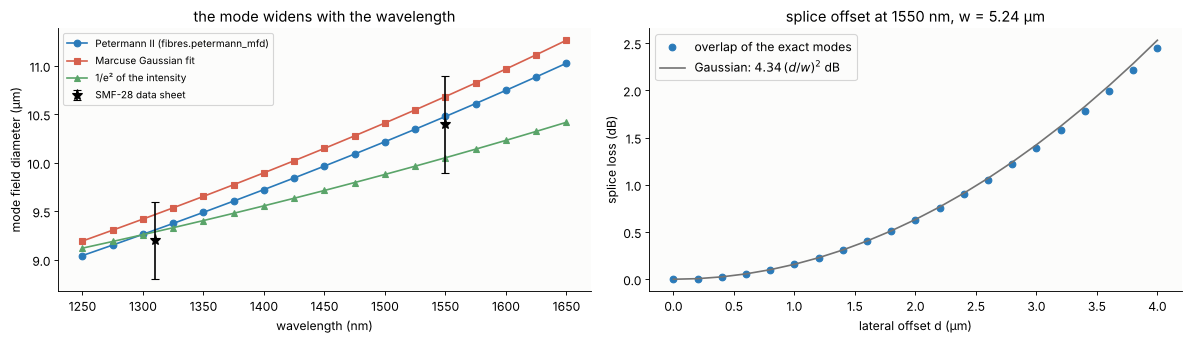

MFD mismatch 10.4/10.4 µm: loss 0.000 dB
MFD mismatch 10.4/9.2 µm: loss 0.065 dB
MFD mismatch 10.4/6.0 µm: loss 1.253 dB


In [7]:
wl_mfd = np.linspace(1.25, 1.65, 17)
pet, mar, e2 = [], [], []
for w in wl_mfd:
    mo = fibres.scalar_mode(smf, w, r_max=30, n_points=3000)
    pet.append(fibres.petermann_mfd(mo))
    mar.append(2*modes.marcuse_mode_field_radius(smf.V(w), smf.a))
    I = mo.u**2
    e2.append(2*np.interp(np.exp(-2), I[::-1]/I.max(), mo.r[::-1]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].plot(wl_mfd*1E3, pet, "o-", color=BLUE, label="Petermann II (fibres.petermann_mfd)")
axes[0].plot(wl_mfd*1E3, mar, "s-", color=RED, label="Marcuse Gaussian fit")
axes[0].plot(wl_mfd*1E3, e2, "^-", color=GREEN, label="1/e² of the intensity")
axes[0].errorbar([1310, 1550], [9.2, 10.4], [0.4, 0.5], fmt="k*", ms=10, capsize=4, label="SMF-28 data sheet")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel("mode field diameter (µm)"); axes[0].legend(fontsize=9)
axes[0].set_title("the mode widens with the wavelength")

# splice loss: lateral offset, exact overlap against the Gaussian estimate
mo = fibres.scalar_mode(smf, 1.55, r_max=30, n_points=3000)
xg, yg, _, _ = grid2d(-25, 25, -25, 25, 301)
field = mo.field(xg, yg)
offsets = np.linspace(0, 4, 21)
eta = []
for dx in offsets:
    shifted = mo.field(xg - dx, yg)
    eta.append(abs(np.sum(np.conj(field)*shifted))**2/(np.sum(abs(field)**2)*np.sum(abs(shifted)**2)))
w_p = fibres.petermann_mfd(mo)/2
axes[1].plot(offsets, -10*np.log10(eta), "o", color=BLUE, label="overlap of the exact modes")
axes[1].plot(offsets, 10*np.log10(np.e)*(offsets/w_p)**2, color=GREY, label=r"Gaussian: $4.34\,(d/w)^2$ dB")
axes[1].set_xlabel("lateral offset d (µm)"); axes[1].set_ylabel("splice loss (dB)")
axes[1].set_title(f"splice offset at 1550 nm, w = {w_p:.2f} µm"); axes[1].legend()
plt.tight_layout()
plt.show()
for w1, w2 in ((5.2, 5.2), (5.2, 4.6), (5.2, 3.0)):
    print("MFD mismatch {:.1f}/{:.1f} µm: loss {:.3f} dB".format(2*w1, 2*w2,
          abs(10*np.log10((2*w1*w2/(w1**2 + w2**2))**2))))

The model fibre lies within the data sheet tolerance. The mode grows by
13 % from 1310 to 1550 nm because V falls and more of the mode spreads into
the cladding. An offset of 1 µm costs 0.15 dB, which is why connectors
centre the cores to well below a micrometre; the Gaussian estimate with the
Petermann radius is excellent. Joining two different fibres costs the
mismatch loss $-10\log_{10}\left(2w_1w_2/(w_1^2 + w_2^2)\right)^2$, small for
similar fibres and 1.3 dB from a standard to a 6 µm high-NA fibre.

## 5. Graded-index modes and their ray families

For profiles other than the step, `fibres.scalar_modes()` solves the scalar
wave equation in $r$ by finite volumes: for each azimuthal order $l$ the
equation for $u(r)$ multiplied by $r$ gives a symmetric tridiagonal matrix,
and the guided eigenvalues $\beta^2 > k^2n_2^2$ come from scipy's tridiagonal
eigensolver in a fraction of a second. For the step profile it reproduces
`modes.lp_modes()` to $10^{-6}$ in $n_{eff}$ (`test_fibres.py`).

The infinite parabolic profile is the harmonic oscillator of quantum
mechanics: its modes have

$$
\beta^2 = k^2n_1^2 - \frac{2kn_1\sqrt{2\Delta}}{a}\,q, \qquad q = 2m + l - 1,
$$

so modes with the same principal number $q$ are degenerate and the groups
are equally spaced in $\beta$ (nearly). Equal spacing is the wave version of
the equal transit times of notebook 115 (light in a fibre): the group delay
$d\beta/d\omega$ is then the same for all groups to first order in $\Delta$.

100 LP modes (l, m) in 0.09 s


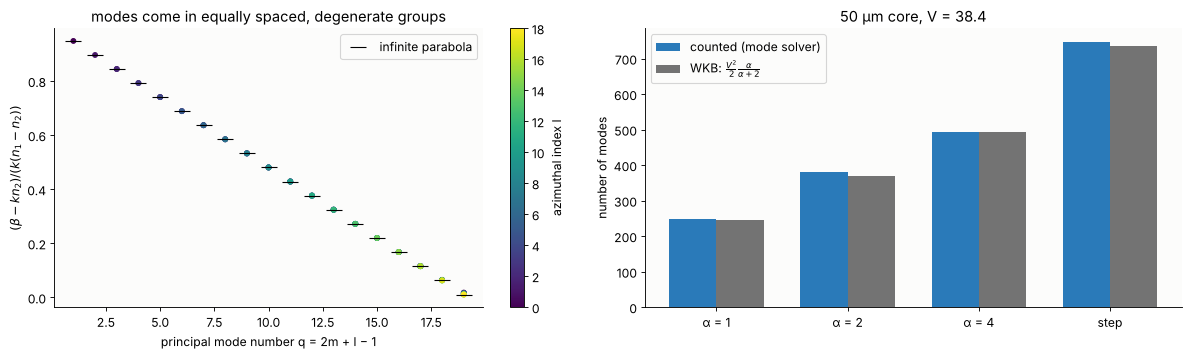

worst deviation from the infinite parabola for q <= 20: 7.0e-05 (relative in beta)


In [8]:
a, n1, Delta, wl = 25.0, 1.47, 0.01, 0.85
n2 = n1*np.sqrt(1 - 2*Delta)
gi = fibres.graded_index(a, 2.0, n1, n2)
t0 = time.time()
gi_modes = gi.modes(wl, r_max=2.5*a, n_points=2500)
print("{} LP modes (l, m) in {:.2f} s".format(len(gi_modes), time.time() - t0))
k = 2*np.pi/wl
q = np.array([2*m.m + m.l - 1 for m in gi_modes])
beta = np.array([m.beta for m in gi_modes])
deg = np.array([2 if m.l == 0 else 4 for m in gi_modes])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sc = axes[0].scatter(q, (beta - k*n2)/(k*(n1 - n2)), c=[m.l for m in gi_modes], cmap="viridis", s=18)
qq = np.arange(1, q.max() + 1)
b_exact = fibres.parabolic_betas(a, n1, Delta, wl, qq)
axes[0].plot(qq, (b_exact - k*n2)/(k*(n1 - n2)), "k_", ms=14, label="infinite parabola")
plt.colorbar(sc, ax=axes[0], label="azimuthal index l")
axes[0].set_xlabel("principal mode number q = 2m + l − 1"); axes[0].set_ylabel(r"$(\beta - kn_2)/(k(n_1 - n_2))$")
axes[0].set_title("modes come in equally spaced, degenerate groups"); axes[0].legend()
# mode count against WKB
alphas = [1.0, 2.0, 4.0, 1E3]
counted, wkb = [], []
for al in alphas:
    f = fibres.graded_index(a, al, n1, n2) if al < 100 else fibres.step_index(a, n1, n2)
    ms = f.modes(wl, r_max=2.5*a, n_points=2500)
    counted.append(sum(2 if m.l == 0 else 4 for m in ms))
    V = f.V(wl)
    wkb.append(V**2/2*al/(al + 2))
axes[1].bar(np.arange(4) - 0.18, counted, 0.36, color=BLUE, label="counted (mode solver)")
axes[1].bar(np.arange(4) + 0.18, wkb, 0.36, color=GREY, label=r"WKB: $\frac{V^2}{2}\frac{\alpha}{\alpha + 2}$")
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(["α = 1", "α = 2", "α = 4", "step"])
axes[1].set_ylabel("number of modes"); axes[1].legend(); axes[1].set_title(f"50 µm core, V = {gi.V(wl):.1f}")
plt.tight_layout()
plt.show()
print("worst deviation from the infinite parabola for q <= 20: {:.1e} (relative in beta)".format(
      max(abs(m.beta - fibres.parabolic_betas(a, n1, Delta, wl, 2*m.m + m.l - 1))/m.beta
          for m in gi_modes if 2*m.m + m.l - 1 <= 20)))

The low groups lie on the infinite parabola; the highest ones feel that the
parabola stops at the core boundary and move slightly. The parabolic core
holds half as many modes as a step core of the same $V$
($V^2/4$ against $V^2/2$).

**Modes and rays.** Each mode has a ray family with the same invariants
$\bar\beta = \beta/k$ and $\bar l = l/(ka)$ (notebook 115, light in a fibre). The rays of that
family oscillate between the two turning radii where
$k^2n^2(r) - l^2/r^2 = \beta^2$ (the caustics), and the mode field fills the
same region, decaying outside. Below, the radial intensity of four modes
with the turning radii of their rays.

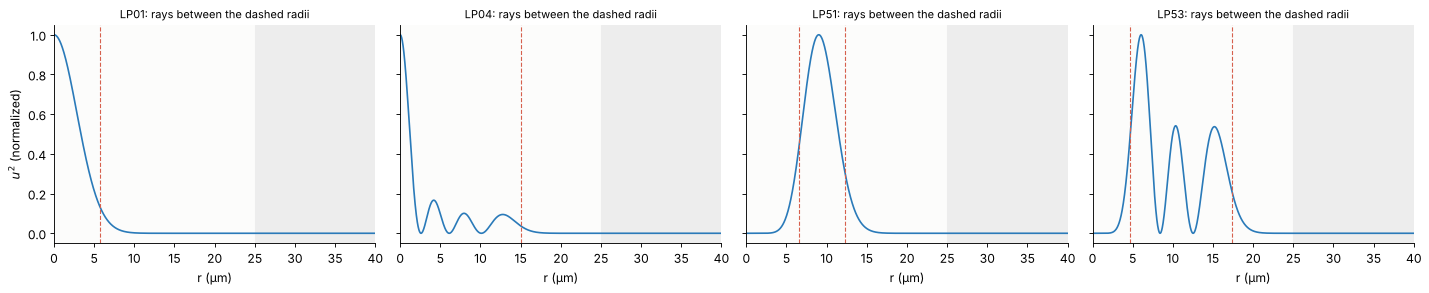

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
pick = [(0, 1), (0, 4), (5, 1), (5, 3)]
rr = np.linspace(1E-3, 2*a, 4000)
for ax, (l, m) in zip(axes, pick):
    mo = [g for g in gi_modes if g.l == l and g.m == m][0]
    I = mo.u**2
    ax.plot(mo.r, I/I.max(), color=BLUE)
    allowed = k**2*gi.n2(rr, wl) - l**2/rr**2 - mo.beta**2 >= 0
    edges = rr[np.nonzero(np.diff(allowed.astype(int)))[0]]
    for e in edges:
        ax.axvline(e, color=RED, ls="--", lw=1)
    ax.axvspan(a, 2*a, color="0.93", zorder=0)
    ax.set_title(f"LP{l}{m}: rays between the dashed radii", fontsize=10)
    ax.set_xlabel("r (µm)"); ax.set_xlim(0, 1.6*a)
axes[0].set_ylabel(r"$u^2$ (normalized)")
plt.tight_layout()
plt.show()

Modes with $l = 0$ reach the axis; modes with large $l$ (strongly skew ray
families) are rings between an inner and an outer caustic. The field leaks
a little beyond the caustics, as a quantum particle tunnels into the
forbidden region.

## 6. Bend loss of a single-mode fibre

A bent fibre radiates: on the outside of the bend the evanescent tail of
the mode would have to travel faster than light in the cladding, and that
part of the field leaves. Marcuse's formula for LP$_{01}$
(`fibres.bend_loss()`) gives the loss per length,

$$
\alpha = \frac{\sqrt{\pi}\,\kappa^2\exp\!\left(-\frac{2\gamma^3}{3\beta^2}R\right)}
{2\gamma^{3/2}V^2\sqrt{R}\,K_1^2(\gamma a)}, \qquad \kappa = U/a,\ \gamma = W/a,
$$

exponential in the bend radius. Because $\gamma$ falls with the wavelength,
long wavelengths are much more sensitive: a bend that is harmless at 1310
nm can cost decibels at 1625 nm. (The formula ignores the stress in the
bent glass, which raises the effective radius by a factor of about 1.3, and
the transitions in and out of the bend.)

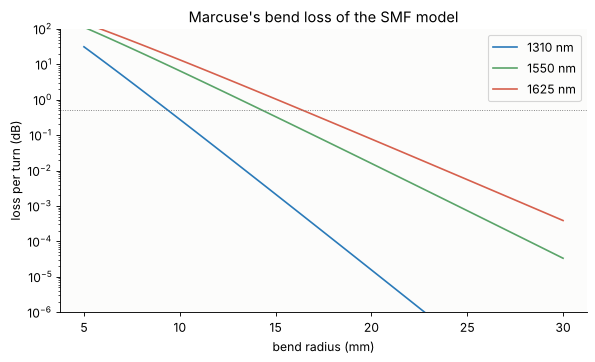

1310 nm: 1 turn at 10 mm 2.77e-01 dB, 10 turns at 15 mm 2.14e-02 dB, 100 turns at 30 mm 7.6e-08 dB
1550 nm: 1 turn at 10 mm 6.52e+00 dB, 10 turns at 15 mm 3.31e+00 dB, 100 turns at 30 mm 3.3e-03 dB
1625 nm: 1 turn at 10 mm 1.33e+01 dB, 10 turns at 15 mm 1.04e+01 dB, 100 turns at 30 mm 3.9e-02 dB


In [10]:
R = np.linspace(5, 30, 101)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for w, c in ((1.31, BLUE), (1.55, GREEN), (1.625, RED)):
    loss_turn = fibres.bend_loss(smf, w, R)*2*np.pi*R*1E-3
    ax.semilogy(R, loss_turn, color=c, label=f"{w*1E3:.0f} nm")
ax.set_ylim(1E-6, 1E2)
ax.axhline(0.5, color=GREY, ls=":", lw=0.8)
ax.set_xlabel("bend radius (mm)"); ax.set_ylabel("loss per turn (dB)")
ax.set_title("Marcuse's bend loss of the SMF model"); ax.legend()
plt.show()
for w in (1.31, 1.55, 1.625):
    print("{:.0f} nm: 1 turn at 10 mm {:.2e} dB, 10 turns at 15 mm {:.2e} dB, 100 turns at 30 mm {:.1e} dB".format(
          w*1E3, fibres.bend_loss(smf, w, 10)*2*np.pi*10E-3, 10*fibres.bend_loss(smf, w, 15)*2*np.pi*15E-3,
          100*fibres.bend_loss(smf, w, 30)*2*np.pi*30E-3))

Between 1310 and 1625 nm the radius for a given loss grows by about 70 %
(0.5 dB per turn at 9.5 mm, 14 mm and 16.5 mm). At small radii the formula
is pessimistic: with the stress correction the measured losses of SMF-28
are about ten times lower.
A standard fibre is specified for 100 turns at 30 mm (at most 0.1 dB at
1625 nm, comfortably met); the bend-insensitive fibres of ITU-T G.657
(10 turns at 15 mm for 0.25 dB or less, 1 turn at 10 mm for 0.75 dB) get
there with a lower-index **trench** around the core, which raises $\gamma$
of the tail without changing the mode field much. With `fibres.w_profile()`
such a profile is one line; notebook 117 (dispersion in fibres) uses it to shape the dispersion.

## Summary

- **Slab:** modes are ray directions that repeat after a round trip,
  $2kn_1d\sin\theta + 2\arg r = 2\pi m$, with the reflection phases from
  `interfaces`; they agree with the finite-difference solver of the FDTD.
- **Step-index fibre:** one parameter, $V = 2\pi a\mathrm{NA}/\lambda$.
  Single mode below 2.405, about $V^2/2$ modes above. The SMF model of
  `fibres.smf28()` (GeO₂-doped core, Fleming's data) has its cutoff at
  1.35 µm.
- **Vector modes:** each LP mode is a group of HE, EH, TE and TM modes split
  by $\propto\Delta^2$ at fixed V, a few $10^{-6}$ for a single-mode fibre.
- **Mode field diameter:** 9.3 µm at 1310 nm and 10.5 µm at 1550 nm
  (Petermann II), within the SMF-28 tolerance. 1 µm of offset costs
  0.15 dB.
- **Graded index:** the radial solver gives equally spaced, degenerate
  mode groups $q = 2m + l - 1$ (the equal transit times of notebook 115, light in a fibre),
  half as many modes as the step ($V^2\alpha/(2(\alpha + 2))$); each mode
  fills the region between the caustics of its ray family.
- **Bend loss** is exponential in the radius and far larger at long
  wavelengths.

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 18 s


## References

- A. W. Snyder and J. D. Love, *Optical Waveguide Theory*, Chapman and
  Hall (1983), chapters 12 to 15 (exact and LP modes, mode groups) and 23
  (bends).
- D. Gloge, "Weakly guiding fibers", Appl. Opt. 10, 2252–2258 (1971).
- K. Okamoto, *Fundamentals of Optical Waveguides*, 2nd ed., Academic
  Press (2006), chapters 2 and 3.
- K. Petermann, "Constraints for fundamental-mode spot size for broadband
  dispersion-compensated single-mode fibres", Electron. Lett. 19, 712–714
  (1983).
- D. Marcuse, "Loss analysis of single-mode fiber splices", Bell Syst.
  Tech. J. 56, 703–718 (1977), and "Curvature loss formula for optical
  fibers", J. Opt. Soc. Am. 66, 216–220 (1976).
- J. W. Fleming, "Dispersion in GeO₂–SiO₂ glasses", Appl. Opt. 23,
  4486–4493 (1984).
- Corning SMF-28 Ultra optical fiber, product information (2014), and
  ITU-T G.652, G.657 and G.650.1.